In [35]:
from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance
import torch
import os 
from datasets import load_dataset
from torchvision import transforms
import numpy as np

In [36]:
DEVICE          = torch.device("cuda:0")
REAL_STATS_FILE = "test_stats_10class.npz"
NUM_CLASSES     = 10
FID_N_SAMPLES   = 500

In [37]:
def get_inception():
    block_idx = InceptionV3.BLOCK_INDEX_BY_DIM[2048]
    model = InceptionV3([block_idx]).to(DEVICE)
    model.eval()
    return model

def get_activations(images, inception):
    """images: (N, 3, H, W) in [-1, 1]"""
    imgs = (images.clamp(-1, 1) + 1) / 2  # → [0, 1]
    imgs = torch.nn.functional.interpolate(imgs, size=(299, 299), mode='bilinear', align_corners=False)
    with torch.no_grad():
        acts = inception(imgs)[0].squeeze(-1).squeeze(-1)
    return acts.cpu().numpy()

def compute_stats(acts):
    mu = np.mean(acts, axis=0)
    sigma = np.cov(acts, rowvar=False)
    return mu, sigma

# ── Precompute real image stats ───────────────────────────────────────────────
def precompute_real_stats(inception):
    if os.path.exists(REAL_STATS_FILE):
        print(f"Loading cached real stats from {REAL_STATS_FILE}")
        data = np.load(REAL_STATS_FILE)
        return data['mu'], data['sigma']

    print("Precomputing real image stats (one-time)...")
    dataset = load_dataset(
        "benjamin-paine/imagenet-1k-64x64",
        cache_dir="/home/magicyu/fuxianhu/datasets/ImageNet64_HF",
        split="train"
    ).filter(lambda x: x["label"] < NUM_CLASSES)

    transform = transforms.Compose([
        transforms.Resize(64), transforms.CenterCrop(64),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])

    indices = torch.randperm(len(dataset))[:FID_N_SAMPLES].tolist()
    batch = dataset[indices]
    real_imgs = torch.stack([transform(img.convert("RGB")) for img in batch["image"]]).to(DEVICE)  # (N, 3, H, W)

    acts = []
    for i in range(0, len(real_imgs), 50):
        acts.append(get_activations(real_imgs[i:i+50], inception))
    acts = np.concatenate(acts, axis=0)
    mu, sigma = compute_stats(acts)
    # np.savez(REAL_STATS_FILE, mu=mu, sigma=sigma)
    print(f"Real stats saved to {REAL_STATS_FILE} ({len(acts)} samples)")
    return mu, sigma

In [38]:
inception = get_inception()
real_mu, real_sigma = precompute_real_stats(inception)

Precomputing real image stats (one-time)...
Real stats saved to test_stats_10class.npz (500 samples)


In [40]:
real_sigma.shape

(2048, 2048)

In [41]:
import matplotlib.pyplot as plt

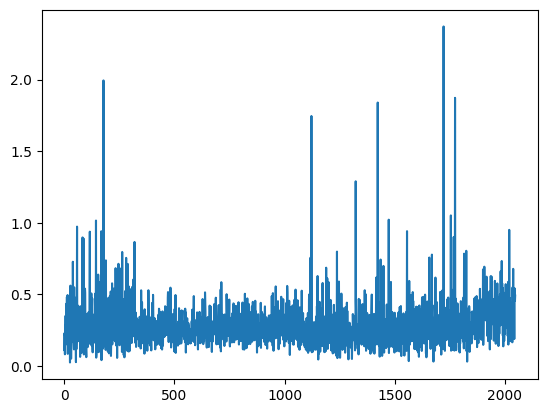

In [42]:
plt.plot(real_mu)

In [44]:
print("Precomputing real image stats (one-time)...")
dataset = load_dataset(
    "benjamin-paine/imagenet-1k-64x64",
    cache_dir="/home/magicyu/fuxianhu/datasets/ImageNet64_HF",
    split="train"
).filter(lambda x: x["label"] < NUM_CLASSES)

transform = transforms.Compose([
    transforms.Resize(64), transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

indices = torch.randperm(len(dataset))[:FID_N_SAMPLES].tolist()
batch = dataset[indices]
real_imgs = torch.stack([transform(img.convert("RGB")) for img in batch["image"]]).to(DEVICE)  # (N, 3, H, W)

Precomputing real image stats (one-time)...


Filter:   0%|          | 0/1281167 [00:00<?, ? examples/s]

In [51]:
indices = torch.randperm(len(dataset))[:FID_N_SAMPLES].tolist()

In [63]:
real_imgs[0]

tensor([[[-0.8902, -0.9059, -0.8902,  ..., -0.8431, -0.8431, -0.8431],
         [-0.8745, -0.8902, -0.8824,  ..., -0.8667, -0.8667, -0.8667],
         [-0.8667, -0.8824, -0.8667,  ..., -0.8824, -0.8902, -0.8902],
         ...,
         [-0.7804, -0.8667, -0.8667,  ..., -0.2706, -0.2784, -0.2784],
         [-0.8510, -0.9137, -0.9059,  ..., -0.3098, -0.3176, -0.3255],
         [-0.8980, -0.8980, -0.8667,  ..., -0.3412, -0.3490, -0.3490]],

        [[-0.8510, -0.8667, -0.8510,  ..., -0.7804, -0.7804, -0.7804],
         [-0.8353, -0.8510, -0.8431,  ..., -0.8039, -0.8039, -0.8039],
         [-0.8039, -0.8196, -0.8275,  ..., -0.8196, -0.8275, -0.8275],
         ...,
         [-0.2627, -0.3490, -0.3490,  ..., -0.1451, -0.1529, -0.1529],
         [-0.3098, -0.3725, -0.3725,  ..., -0.1843, -0.1922, -0.2000],
         [-0.3412, -0.3412, -0.3333,  ..., -0.2157, -0.2235, -0.2235]],

        [[-0.8275, -0.8431, -0.8275,  ..., -0.7569, -0.7569, -0.7569],
         [-0.8118, -0.8275, -0.8196,  ..., -0